# One hand, from the deal to the score, and was the bid right?

This notebook takes one deal through everything the project can now do, then does the same for two thousand deals:

1. **Deal** a hand and look at it: points, shape, and what the cards allow with perfect play (a *double-dummy* solution).
2. **Bid**: the auction, round by round, with the reason for every call (`PointsAndFit`, a small points-and-fit system).
3. **Play**: the contract played trick by trick, once by a simple strategy and once by a player that **counts cards**.
4. **Score**: duplicate scoring of what happened against what was possible.
5. **Judge the bidding** over 2,000 deals with a **confusion matrix**: the bid reached against the highest contract that makes.

*Needs the double-dummy solver (the `dd` dependency group), which has wheels for Python 3.12 and 3.13.*

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import HTML, display
from matplotlib.colors import LogNorm
from matplotlib.patches import Rectangle

from Bridge import DoubleDummy as DD
from Bridge import Evaluation as E
from Bridge import Probability as P
from Bridge.Auction import run_auction
from Bridge.Bid import Bid
from Bridge.Contract import SYMBOLS
from Bridge.Deck import Deck
from Bridge.Hand import Hand
from Bridge.Harness import run_batches
from Bridge.Position import Position
from Bridge.Round import Round, countingHigh, simpleHigh
from Bridge.Scoring import score
from Bridge.Table import Table

assert DD.AVAILABLE, "this notebook needs the double-dummy solver: `uv sync` on Python 3.12 or 3.13"
sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 13})
SEATS = Position.positions
STRAINS = Bid.strains  # clubs, diamonds, hearts, spades, notrump

## Display helpers

Hands, the double-dummy table, the auction and the play are shown as small HTML tables (suit symbols, red for hearts and diamonds).

In [2]:
RED = "#c0392b"
SYMBOL = SYMBOLS  # clubs, diamonds, hearts, spades, notrump -> symbols

def suit_html(suit):
    colour = RED if suit in ("hearts", "diamonds") else "inherit"
    return f'<span style="color:{colour}">{SYMBOL[suit]}</span>'

def rank_text(card):
    return "10" if str(card.value) == "0" else str(card.value)

def card_html(card, bold=False):
    text = f"{suit_html(str(card.suit))}{rank_text(card)}"
    return f"<b>{text}</b>" if bold else text

def bid_html(bid):
    if bid is None:
        return ""
    if bid.isPass:
        return '<span style="color:#888">pass</span>'
    return f"{bid.value}{suit_html(bid.suit) if bid.suit != 'notrump' else 'NT'}"

def holdings_html(cards, played=()):
    """one line per suit, highest first; cards in `played` are greyed out"""
    played = {c.code for c in played}
    lines = []
    for suit in ("spades", "hearts", "diamonds", "clubs"):
        ranks = sorted([c for c in cards if str(c.suit) == suit], key=lambda c: -c.rank)
        text = " ".join(f'<span style="color:#aaa;text-decoration:line-through">{rank_text(c)}</span>' if c.code in played
                        else rank_text(c) for c in ranks) or "&mdash;"
        lines.append(f"{suit_html(suit)}&nbsp;{text}")
    return "<br>".join(lines)

def hand_box(seat, hand, played=(), note=""):
    cards = hand.original
    shape = "-".join(str(n) for _, n in hand.distro())
    caption = f"<b>{seat.title()}</b> <small style='color:#888'>{hand.hcp() if len(hand.original) == 13 else ''} points, {shape}</small>"
    return (f'<div style="border:1px solid #999;border-radius:6px;padding:6px 12px;text-align:left;min-width:170px;'
            f'display:inline-block;line-height:1.5">{caption}<br>{holdings_html(cards, played)}{note}</div>')

def compass(boxes, centre=""):
    cell = lambda html: f'<td style="padding:4px;text-align:center;vertical-align:middle">{html}</td>'
    return ('<table style="border-collapse:collapse;margin:8px 0"><tr>' + cell("") + cell(boxes["north"]) + cell("") + "</tr><tr>"
            + cell(boxes["west"]) + cell(centre) + cell(boxes["east"]) + "</tr><tr>" + cell("") + cell(boxes["south"]) + cell("")
            + "</tr></table>")

def deal_html(hands, dealer=None, vulnerable="none"):
    boxes = {seat: hand_box(seat, hands[i]) for i, seat in enumerate(SEATS)}
    centre = f'<div style="border:1px dashed #bbb;padding:10px;color:#666">Dealer: <b>{dealer}</b><br>Vulnerable: <b>{vulnerable}</b></div>' if dealer else ""
    return compass(boxes, centre)

def table_html(header, rows, styles=None, caption=""):
    th = "".join(f'<th style="padding:3px 10px;border-bottom:2px solid #888;text-align:center">{h}</th>' for h in header)
    body = ""
    for r, row in enumerate(rows):
        body += "<tr>" + "".join(
            f'<td style="padding:3px 10px;text-align:center;{(styles or {}).get((r, c), "")}">{cell}</td>' for c, cell in enumerate(row)) + "</tr>"
    cap = f'<caption style="caption-side:top;text-align:left;font-weight:bold;padding-bottom:4px">{caption}</caption>' if caption else ""
    return f'<table style="border-collapse:collapse;margin:6px 0">{cap}<tr>{th}</tr>{body}</table>'

def dd_html(table):
    """tricks the declaring side takes, by strain (rows) and declarer (columns)"""
    rows, styles = [], {}
    order = [("notrump", 4), ("spades", 3), ("hearts", 2), ("diamonds", 1), ("clubs", 0)]
    for r, (strain, s) in enumerate(order):
        rows.append([suit_html(strain) if strain != "notrump" else "NT"] + [int(table[s][seat]) for seat in range(4)])
        for c in range(4):
            tricks = int(table[s][c])
            styles[(r, c + 1)] = f"background:rgba(39,174,96,{0.08 + 0.07 * max(tricks - 6, 0):.2f})" + (";font-weight:bold" if tricks >= 7 else "")
    return table_html(["", "North", "East", "South", "West"], rows, styles, "Tricks the declaring side takes, best play by everyone")

def auction_html(result):
    rows = []
    for row in result.rounds():
        rows.append([bid_html(b) if b is not None else "" for b in row])
    header = [f"{s.title()}{' (dealer)' if s == result.dealer else ''}" for s in SEATS]
    return table_html(header, rows, caption="The auction")

def reasons_html(result):
    items = "".join(f"<li><b>{c.seat.title()}</b> {bid_html(c.bid)}: {c.reason}</li>" for c in result.calls
                    if not c.reason.startswith("the other side opened"))
    return f"<ol style='line-height:1.6'>{items}</ol>"

def play_html(rnd, contract):
    """the trick-by-trick table of a played Round"""
    rows, styles = [], {}
    ours = 0
    for t, (trick, winner) in enumerate(zip(rnd.tricks, rnd.winners)):
        won = Position.side(winner) == contract.side
        ours += won
        cells = []
        for c, seat in enumerate(SEATS):
            card = trick.getCard(seat)
            lead = "&rarr;&nbsp;" if seat == trick.leader else ""
            cells.append(lead + card_html(card, bold=(seat == winner)))
            if seat == winner:
                styles[(t, c + 1)] = "background:rgba(39,174,96,0.18)"
        rows.append([t + 1] + cells + [winner.title(), f"{ours}&ndash;{t + 1 - ours}"])
    header = ["Trick"] + [s.title() for s in SEATS] + ["Won by", f"{contract.declarer.title()}'s side so far"]
    return table_html(header, rows, styles, "&rarr; marks the lead, the winning card is bold")

## 1. Deal a hand

A deal is shuffled from a seeded generator, so it can be reproduced. Next to each hand: its high card points (A=4, K=3, Q=2, J=1), its shape, and
how rare that many points are, from the **exact** distribution (`Probability.hcp_pmf`).

In [3]:
EXAMPLE = 234           # the 235th deal from this seed: one that shows a lot
SEED = 2026
rng = np.random.default_rng(SEED)
for _ in range(EXAMPLE + 1):
    deck = Deck(shuffle=3, rng=rng)
hands = list(deck.deal())
dealer = SEATS[EXAMPLE % 4]
display(HTML(deal_html(hands, dealer, "none")))

exact = P.hcp_pmf(13)
summary = pd.DataFrame({
    "points": [h.hcp() for h in hands],
    "shape (S-H-D-C)": ["-".join(str(n) for _, n in h.distro()) for h in hands],
    "balanced": [h.balanced() for h in hands],
    "chance of this many points or more": [f"{exact[h.hcp():].sum():.1%}" for h in hands],
}, index=[s.title() for s in SEATS])
summary

,"North 15 points, 1-1-8-3♠ Q♥ 8♦ A K Q J 8 7 4 2♣ K 6 4",
"West 5 points, 4-4-3-2♠ 8 6 5 3♥ K 9 5 2♦ 10 6 5♣ Q 8",Dealer: southVulnerable: none,"East 5 points, 1-6-1-5♠ J♥ Q J 10 7 6 3♦ 3♣ J 10 7 5 2"
,"South 15 points, 7-2-1-3♠ A K 10 9 7 4 2♥ A 4♦ 9♣ A 9 3",


,points,shape (S-H-D-C),balanced,chance of this many points or more
North,15,1-1-8-3,False,14.2%
East,5,1-6-1-5,False,91.2%
South,15,7-2-1-3,False,14.2%
West,5,4-4-3-2,True,91.2%


### What the cards allow

With all four hands visible and perfect play (*double-dummy*, solved by the DDS solver), this is how many tricks each declarer's side takes in each strain.
The solver is checked in the test suite against a brute-force search of its own, and it is far faster than a search written in Python.

In [4]:
table = DD.dd_table(hands)
display(HTML(dd_html(table)))
best = {side: DD.highest_contract(table, side) for side in ("ns", "ew")}
print(f"highest contract that makes: north-south {best['ns']}, east-west {best['ew']}")
print(f"best double-dummy score: north-south {E.best_dd_score(table, 'ns')}, east-west {E.best_dd_score(table, 'ew')}")

,North,East,South,West
NT,13,0,13,0
♠,13,0,13,0
♥,5,8,5,8
♦,13,0,13,0
♣,10,3,10,3


highest contract that makes: north-south 7 notrump, east-west 2 hearts
best double-dummy score: north-south 1520, east-west 110


## 2. The auction

`PointsAndFit` is a small system, simple enough to read in a minute: points (A=4, K=3, Q=2, J=1) and fit.

| call | rule |
|---|---|
| open | 12+ points; 1NT with a balanced 15-17, 2NT with a balanced 20+; otherwise 1 of the longest major (5+ cards), else the longer minor |
| respond to 1 of a suit | with support (3 cards for a major, 5 for a minor) raise by points (6-9 to the 2 level, 10-12 to 3, 13-16 game, 17+ slam); else a new suit of 4+ cards (the 2 level needs 10+ points; the opener must bid again); else notrump by points |
| respond to 1NT / 2NT | pass, sign off in a 6-card major, invite, or bid game or slam by points |
| the opener's second call | picks the contract: opener's points plus the middle of the range the response showed gives the combined points, played at the level that calls for, in the major that fits, else the opener's own long suit, else notrump (20-22 one level, 23-25 part score, 26+ game, 33+ slam) |
| later | a slam raise if the two hands add up to 33 or more |

The side that did not open stays silent. Every call below comes with its reason.

In [5]:
result = run_auction(hands, dealer)
display(HTML(auction_html(result)))
display(HTML(reasons_html(result)))

North,East,South (dealer),West
,,1♠,pass
2♦,pass,4♠,pass
pass,pass,,


In [6]:
contract = result.contract
dd_tricks = int(table[STRAINS.index(contract.strain)][SEATS.index(contract.declarer)])
print(f"contract: {contract}   (needs {contract.tricks_needed} tricks)")
print(f"declarer {contract.declarer}, dummy {contract.dummy}, opening lead by {contract.opening_leader}")
print(f"double-dummy tricks for this contract: {dd_tricks}")
print(f"highest contract that makes for {contract.side}: {best[contract.side]}  ->  the bid reached was "
      f"{'correct' if best[contract.side] == contract.bid else 'an overbid' if best[contract.side] is None or contract.bid > best[contract.side] else 'an underbid'}")

contract: 4♠ by south   (needs 10 tricks)
declarer south, dummy north, opening lead by west
double-dummy tricks for this contract: 13
highest contract that makes for ns: 7 notrump  ->  the bid reached was an underbid


## 3. The play

The player on declarer's left makes the opening lead, then **dummy** (declarer's partner) puts their hand on the table. Two strategies play all four seats:

* `simpleHigh` leads its highest card, and when following wins the trick if it can, otherwise plays low.
* `countingHigh` is the same, but it **counts cards**: it keeps track of every card played and who has shown out of what, and before anything else it leads a card that is certain to win (the highest card still out in its suit, with no trump left to ruff it).

In [7]:
def play(contract, hands, strategy):
    """play the contract with `strategy` at every seat on fresh copies of the hands"""
    rnd = Round(Table(), [Hand(h.original) for h in hands], contract.trump, [strategy] * 4, declarer=contract.declarer)
    ns, ew = rnd.play()
    return rnd, (ns if contract.side == "ns" else ew)

rnd_simple, tricks_simple = play(contract, hands, simpleHigh)
display(HTML(f"<h4>simpleHigh: {contract.declarer.title()}'s side takes {tricks_simple} tricks</h4>" + play_html(rnd_simple, contract)))

Trick,North,East,South,West,Won by,South's side so far
1,♥8,♥3,♥A,→ ♥K,South,1–0
2,♠Q,♠J,→ ♠A,♠3,South,2–0
3,♣4,♣2,→ ♣A,♣8,South,3–0
4,♦2,♦3,→ ♠K,♠5,South,4–0
5,♦4,♣5,→ ♠10,♠6,South,5–0
6,♣6,♥6,→ ♠9,♠8,South,6–0
7,♦A,♥7,→ ♦9,♦10,North,7–0
8,→ ♦K,♣7,♠2,♦5,South,8–0
9,♣K,♣10,→ ♣9,♣Q,North,9–0
10,→ ♦Q,♥10,♠4,♦6,South,10–0


In [8]:
rnd_count, tricks_count = play(contract, hands, countingHigh)
display(HTML(f"<h4>countingHigh: {contract.declarer.title()}'s side takes {tricks_count} tricks</h4>" + play_html(rnd_count, contract)))
first_difference = next((t for t, (a, b) in enumerate(zip(rnd_simple.tricks, rnd_count.tricks)) if list(a) != list(b)), None)
print(f"the two plays first differ at trick {first_difference + 1}" if first_difference is not None else "the two plays are identical")

Trick,North,East,South,West,Won by,South's side so far
1,♥8,♥3,♥A,→ ♥K,South,1–0
2,♠Q,♠J,→ ♠A,♠3,South,2–0
3,♦2,♣2,→ ♠K,♠5,South,3–0
4,♣4,♦3,→ ♠10,♠6,South,4–0
5,♦4,♣5,→ ♠9,♠8,South,5–0
6,♣6,♣7,→ ♣A,♣8,South,6–0
7,♦7,♥6,→ ♠7,♥2,South,7–0
8,♦8,♥7,→ ♠4,♥5,South,8–0
9,♦J,♣10,→ ♠2,♦5,South,9–0
10,♦A,♥10,→ ♦9,♦10,North,10–0


the two plays first differ at trick 3


### What a player who counts knows

Three tricks in, here is what *declarer* knows (their own hand, dummy, every card played, and who has shown out), and what follows from it.
With two hidden hands the chance that a given card is in a given hand is **exact**: the cards each opponent still holds are known, and so are the suits they are out of
(*vacant places*), so no simulation is needed. Here one opponent has already shown out of a suit, so every remaining card of that suit is with the other, and that leaves the other cards more likely to be with the hand that has the free places, not 50-50.

In [9]:
rnd = Round(Table(), [Hand(h.original) for h in hands], contract.trump, [countingHigh] * 4, declarer=contract.declarer)
leader = contract.opening_leader
TRICKS = 3
for _ in range(TRICKS):
    leader = rnd.play_trick(leader)[1]
k = rnd.knowledge[SEATS.index(contract.declarer)]
lho, rho = Position.index2pos(contract.declarer, 1), Position.index2pos(contract.declarer, 3)
voids = [f"{s} is out of {suit}" for s in (lho, rho) for suit in ("spades", "hearts", "diamonds", "clubs") if k.is_void(s, suit)]
print(f"after {TRICKS} tricks {contract.declarer} knows: {len(k.unseen())} unseen cards; {lho} still holds {k.cards_left(lho)}, "
      f"{rho} holds {k.cards_left(rho)}; shown out: {', '.join(voids) or 'nobody'}")
rows = []
for suit in ("spades", "hearts", "diamonds", "clubs"):
    unseen = k.unseen(suit)
    if not unseen:
        rows.append([suit_html(suit), "&mdash;", "", "", ""])
        continue
    top = unseen[0]
    rows.append([suit_html(suit), " ".join(rank_text(c) for c in unseen), card_html(top),
                 f"{k.probability_holds(lho, top):.0%}", f"{k.probability_holds(rho, top):.0%}"])
display(HTML(table_html(["suit", "unseen cards", "highest unseen", f"{lho} holds it", f"{rho} holds it"], rows,
                        caption=f"What {contract.declarer} knows after {TRICKS} tricks")))
print(f"vacant places: {lho} has {k.vacant_places(lho)} places for a card of a suit nobody is out of, {rho} has {k.vacant_places(rho)}")

after 3 tricks south knows: 20 unseen cards; west still holds 10, east holds 10; shown out: east is out of spades


suit,unseen cards,highest unseen,west holds it,east holds it
♠,8 6,♠8,100%,0%
♥,Q J 10 9 7 6 5 2,♥Q,44%,56%
♦,10 6 5 3,♦10,44%,56%
♣,Q J 10 8 7 5,♣Q,44%,56%


vacant places: west has 8 places for a card of a suit nobody is out of, east has 10


## 4. The score

Duplicate scoring: contract points, bonuses for game and slam, overtricks, and penalties for going down (non-vulnerable here).

In [10]:
def result_text(c, tricks):
    return f"made {tricks - c.tricks_needed:+d}".replace("+0", "exactly") if tricks >= c.tricks_needed else f"down {c.tricks_needed - tricks}"

rows = []
for label, tricks in (("played with simpleHigh", tricks_simple), ("played with countingHigh", tricks_count),
                      ("double-dummy (perfect play)", dd_tricks)):
    s = score(contract, tricks)
    rows.append([label, tricks, result_text(contract, tricks), s, s if contract.side == "ns" else -s])
scores = pd.DataFrame(rows, columns=["", "tricks", f"{contract}", "score for declarer", "north-south score"]).set_index("")
display(scores)
best_score = E.best_dd_score(table, contract.side)
print(f"the best contract on these cards would have scored {best_score} for {contract.side}; "
      f"the contract reached scored {score(contract, tricks_count)} with counting, so {best_score - score(contract, tricks_count)} points were left on the table.")

,tricks,4♠ by south,score for declarer,north-south score
,,,,
played with simpleHigh,11,made +1,450,450
played with countingHigh,13,made +3,510,510
double-dummy (perfect play),13,made +3,510,510


the best contract on these cards would have scored 1520 for ns; the contract reached scored 510 with counting, so 1010 points were left on the table.


## 5. Was the bid right? 2,000 deals

`Evaluation.evaluate` runs one deal after another: the auction, the double-dummy table, the contract played by both strategies, and the scores. It is a `Harness` task, so the
same call scales over many deals. **Correct** means the highest contract that makes (by level, then strain: clubs, diamonds, hearts, spades, notrump) was the one bid.
A bid above it is an **overbid**, below it an **underbid**.

In [11]:
N = 2000
t0 = time.perf_counter()
rows = run_batches(E.evaluate, N, seed=SEED, batch_size=250, workers=1)  # the solver uses all cores itself
print(f"{N:,} deals in {time.perf_counter() - t0:.0f} s  ({(time.perf_counter() - t0) / N * 1000:.0f} ms a deal, almost all of it the double-dummy solver)")
C = E.COL
passed = rows[:, C["passed_out"]] == 1
contracts = rows[~passed]
print(f"{passed.mean():.1%} of deals were passed out; {len(contracts):,} contracts were played")

2,000 deals in 99 s  (50 ms a deal, almost all of it the double-dummy solver)
3.5% of deals were passed out; 1,929 contracts were played


,tricks,contract made,score for declarer
simpleHigh,8.19,57.2%,80
countingHigh,8.23,57.7%,84
double-dummy,8.57,65.5%,134


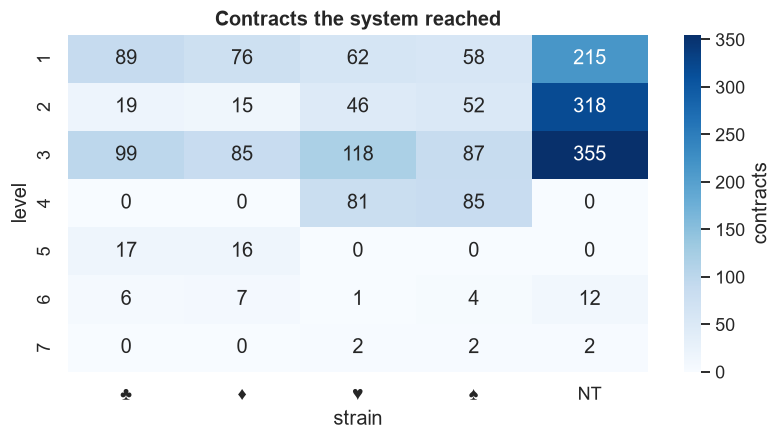

In [12]:
need = contracts[:, C["level"]] + 6
summary = pd.DataFrame({
    "tricks": [contracts[:, C["tricks_simple"]].mean(), contracts[:, C["tricks_counting"]].mean(), contracts[:, C["dd_tricks"]].mean()],
    "contract made": [(contracts[:, C["tricks_simple"]] >= need).mean(), (contracts[:, C["tricks_counting"]] >= need).mean(),
                      (contracts[:, C["dd_tricks"]] >= need).mean()],
    "score for declarer": [contracts[:, C["score_simple"]].mean(), contracts[:, C["score_counting"]].mean(), contracts[:, C["score_dd"]].mean()],
}, index=["simpleHigh", "countingHigh", "double-dummy"])
display(summary.style.format({"tricks": "{:.2f}", "contract made": "{:.1%}", "score for declarer": "{:.0f}"}))

level_strain = pd.crosstab(contracts[:, C["level"]], [STRAINS[s] for s in contracts[:, C["strain"]]]).reindex(columns=list(STRAINS), fill_value=0)
level_strain.index.name, level_strain.columns.name = "level", "strain"
fig, ax = plt.subplots(figsize=(7.5, 4.2))
sns.heatmap(level_strain, annot=True, fmt="d", cmap="Blues", cbar_kws={"label": "contracts"}, ax=ax,
            xticklabels=[SYMBOL[s] for s in level_strain.columns])
ax.set_title("Contracts the system reached")
plt.tight_layout()
plt.show()

### The confusion matrix

Rows are the bid that was reached, columns the highest bid that makes double-dummy for the side that bid (the first row/column is "nothing": everyone passed, or nothing makes). The
**diagonal** is correct. Cells **below** it are overbids (the bid was higher than what makes), **above** it are underbids. First all 35 bids, then the same counts by kind of contract.

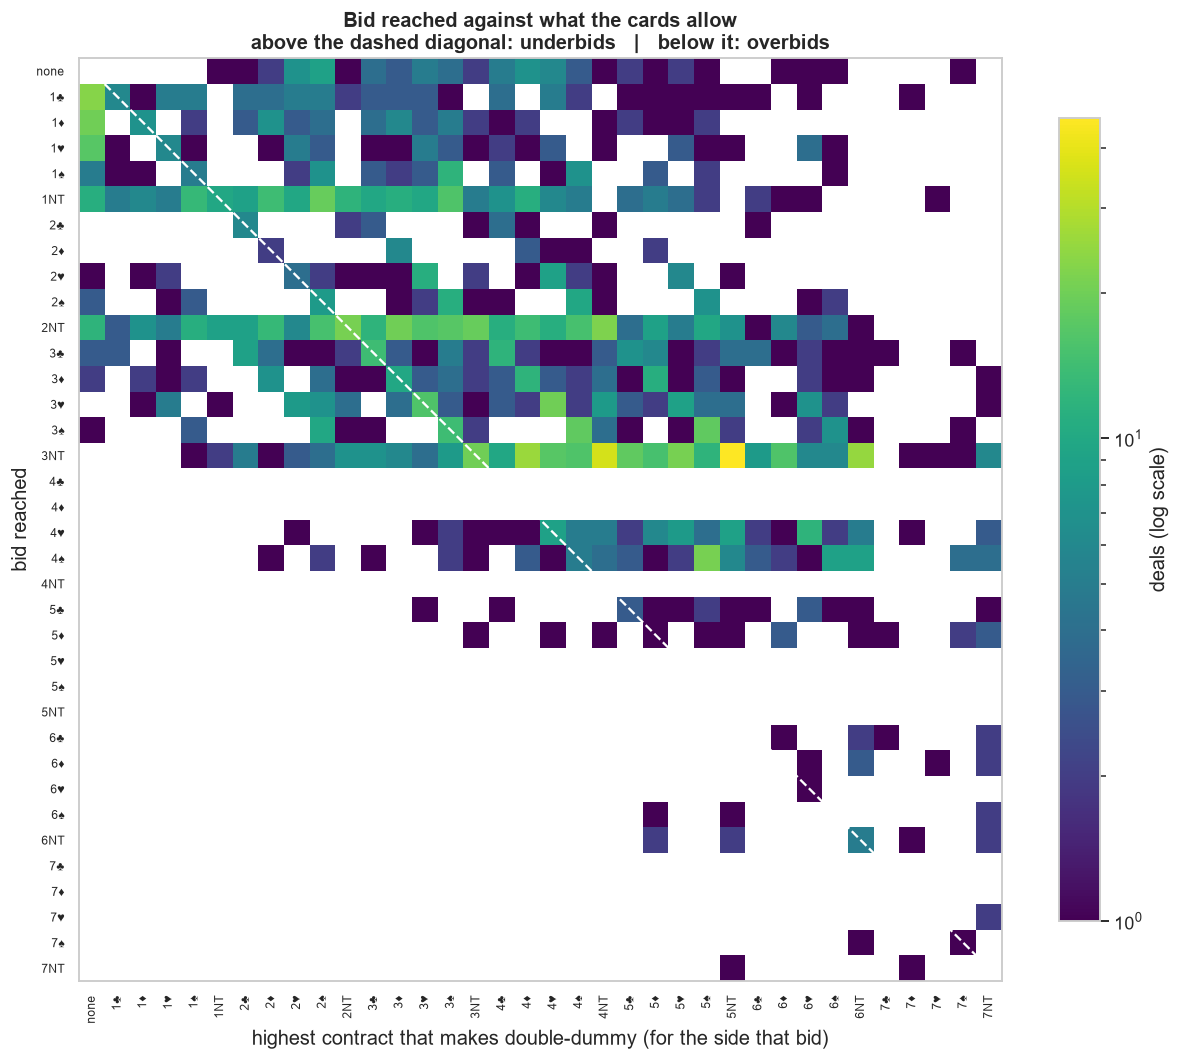

In [13]:
def bid_label(i):
    return "none" if i == 0 else f"{(i - 1) // 5 + 1}{SYMBOL[STRAINS[(i - 1) % 5]]}"

m = E.confusion_matrix(rows)
fig, ax = plt.subplots(figsize=(11.5, 10))
im = ax.imshow(np.where(m > 0, m, np.nan), cmap="viridis", norm=LogNorm(1, m.max()))
ax.plot([-0.5, 35.5], [-0.5, 35.5], color="w", ls="--", lw=1.5)
ax.set_xticks(range(36), [bid_label(i) for i in range(36)], rotation=90, fontsize=8)
ax.set_yticks(range(36), [bid_label(i) for i in range(36)], fontsize=8)
ax.set_xlabel("highest contract that makes double-dummy (for the side that bid)")
ax.set_ylabel("bid reached")
ax.set_title("Bid reached against what the cards allow\nabove the dashed diagonal: underbids   |   below it: overbids")
fig.colorbar(im, ax=ax, label="deals (log scale)", shrink=0.8)
ax.grid(False)
plt.tight_layout()
plt.show()

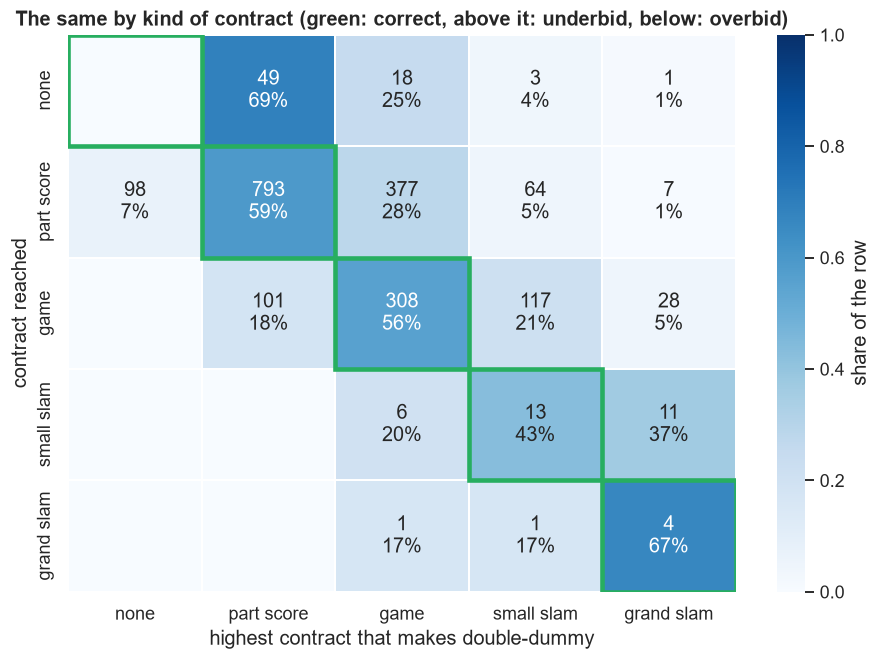

by exact bid:  correct 8.7%, overbid 18.9%, underbid 72.4%
by kind of contract:  correct 55.9%, overbid 10.3%, underbid 33.8%


,underbid,correct,overbid,deals
none,71,0,0,71
part score,448,793,98,1339
game,145,308,101,554
small slam,11,13,6,30
grand slam,0,4,2,6


In [14]:
c = E.category_matrix(rows)
share = c / c.sum(axis=1, keepdims=True).clip(min=1)
labels = np.array([[f"{c[i, j]:,}\n{100 * share[i, j]:.0f}%" if c[i, j] else "" for j in range(5)] for i in range(5)])
fig, ax = plt.subplots(figsize=(8.5, 6.2))
sns.heatmap(share, annot=labels, fmt="", cmap="Blues", vmin=0, vmax=1, cbar_kws={"label": "share of the row"}, ax=ax,
            xticklabels=E.CATEGORIES, yticklabels=E.CATEGORIES, linewidths=1, linecolor="white")
for i in range(5):
    ax.add_patch(Rectangle((i, i), 1, 1, fill=False, edgecolor="#27ae60", lw=3))
ax.set_xlabel("highest contract that makes double-dummy")
ax.set_ylabel("contract reached")
ax.set_title("The same by kind of contract (green: correct, above it: underbid, below: overbid)")
plt.tight_layout()
plt.show()

ou = E.over_under(rows)
by_category = pd.DataFrame({E.CATEGORIES[i]: {"underbid": c[i, i + 1:].sum(), "correct": c[i, i], "overbid": c[i, :i].sum()} for i in range(5)}).T
by_category["deals"] = by_category.sum(axis=1)
print(f"by exact bid:  correct {ou['correct'] / N:.1%}, overbid {ou['overbid'] / N:.1%}, underbid {ou['underbid'] / N:.1%}")
print(f"by kind of contract:  correct {np.trace(c) / N:.1%}, overbid {np.tril(c, -1).sum() / N:.1%}, underbid {np.triu(c, 1).sum() / N:.1%}")
by_category

### A fairer yardstick: points left on the table

"Highest bid that makes" is a strict bar: it ranks by bid order, so 4 spades counts as higher than 3NT even though they score about the same, and double-dummy assumes perfect defence.
So alongside it, the **regret** of each deal: the best score the side could have got with any contract that makes double-dummy, minus what the reached contract scored (when played by `countingHigh`).

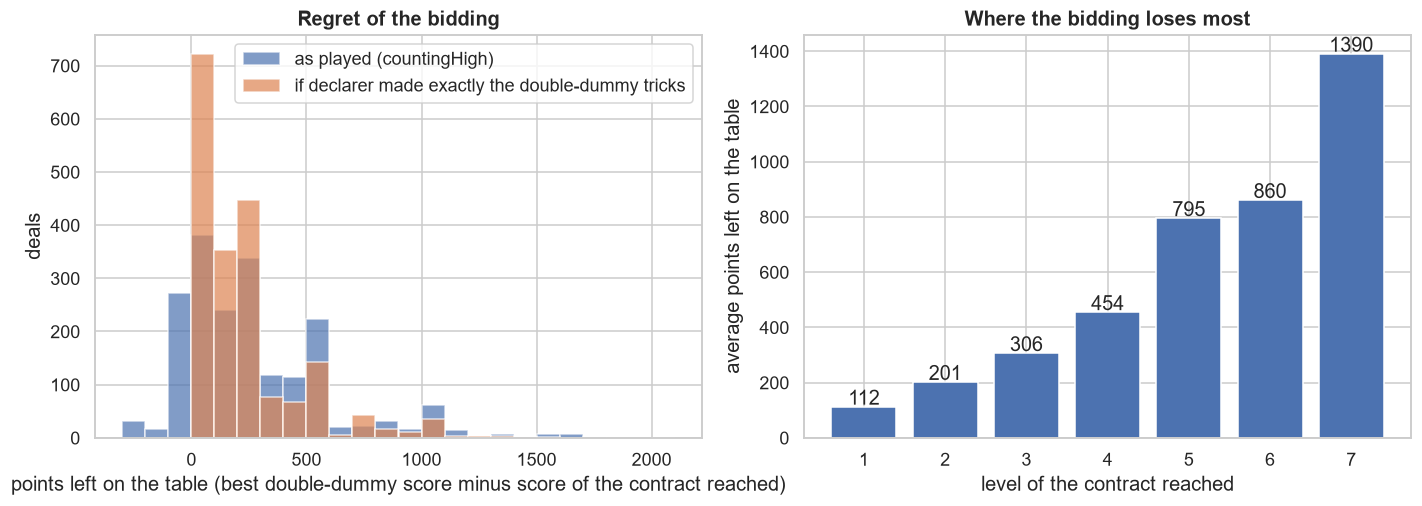

average regret: 264 points as played, 215 with perfect play of the contract reached; passing out cost 256 points on average over the 71 passed-out deals


In [15]:
regret_count = contracts[:, C["best_score"]] - contracts[:, C["score_counting"]]
regret_dd = contracts[:, C["best_score"]] - contracts[:, C["score_dd"]]
passed_regret = rows[passed, C["best_score"]]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))
bins = np.arange(-300, 2101, 100)
ax1.hist(np.clip(regret_count, -300, 2100), bins=bins, alpha=0.7, label="as played (countingHigh)")
ax1.hist(np.clip(regret_dd, -300, 2100), bins=bins, alpha=0.7, label="if declarer made exactly the double-dummy tricks")
ax1.set_xlabel("points left on the table (best double-dummy score minus score of the contract reached)")
ax1.set_ylabel("deals")
ax1.set_title("Regret of the bidding")
ax1.legend()
levels = sorted(set(contracts[:, C["level"]]))
means = [regret_count[contracts[:, C["level"]] == l].mean() for l in levels]
ax2.bar([str(l) for l in levels], means, color="C0")
for x, (l, v) in enumerate(zip(levels, means)):
    ax2.text(x, v + 8, f"{v:.0f}", ha="center")
ax2.set_xlabel("level of the contract reached")
ax2.set_ylabel("average points left on the table")
ax2.set_title("Where the bidding loses most")
plt.tight_layout()
plt.show()
print(f"average regret: {regret_count.mean():.0f} points as played, {regret_dd.mean():.0f} with perfect play of the contract reached; "
      f"passing out cost {passed_regret.mean():.0f} points on average over the {passed.sum()} passed-out deals")

### What if the system opened lighter or tighter?

The double-dummy solver is the slow part and the deals do not change, so solve 800 deals once and rerun only the auctions with different opening thresholds.

800 deals solved in 37 s


,passed out,correct (exact bid),overbid,underbid,correct (kind),average regret
open with,,,,,,
10,0.0%,7.4%,20.8%,71.9%,55.4%,261
11,0.1%,7.1%,19.4%,73.5%,55.8%,274
12,3.6%,6.5%,17.6%,75.9%,54.6%,282
13,14.1%,4.9%,12.6%,82.5%,48.5%,292
14,29.8%,3.8%,9.0%,87.2%,39.1%,306
15,47.5%,2.4%,5.6%,92.0%,30.1%,329


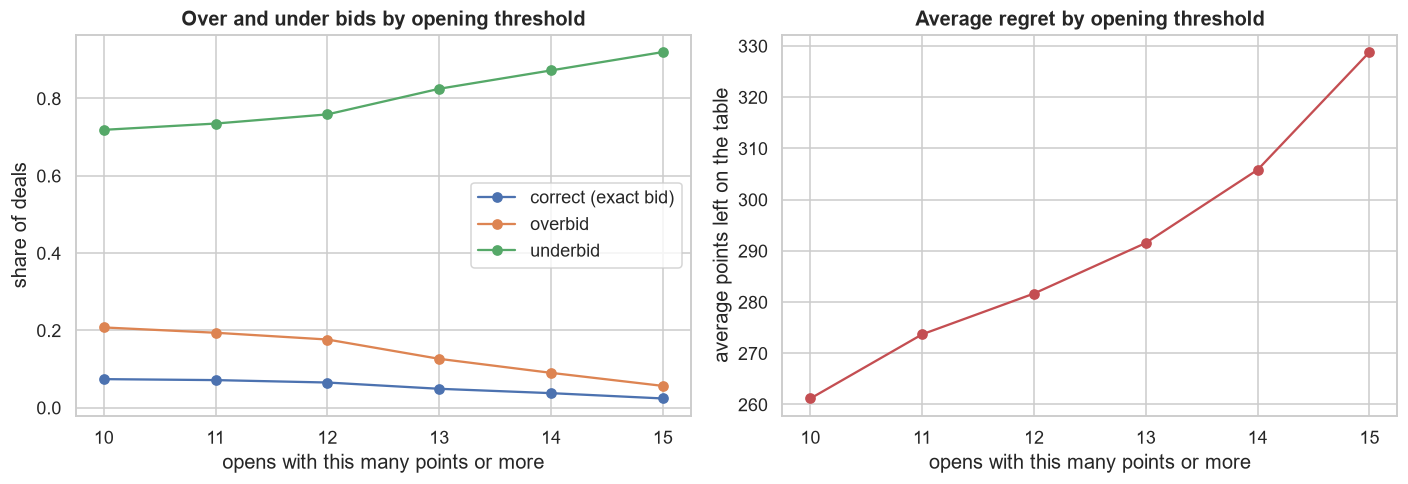

In [16]:
M, SEED2 = 800, 77
deals = E.deal_many(np.random.default_rng(SEED2), M)
t0 = time.perf_counter()
tables = DD.dd_tables(deals)
print(f"{M} deals solved in {time.perf_counter() - t0:.0f} s")
sweep = []
for threshold in (10, 11, 12, 13, 14, 15):
    r = E.evaluate(np.random.default_rng(SEED2), M, open_hcp=threshold, tables=tables)
    played = r[:, C["passed_out"]] == 0
    ou_k = E.over_under(r)
    cm = E.category_matrix(r)
    sweep.append({"open with": threshold, "passed out": 1 - played.mean(),
                  "correct (exact bid)": ou_k["correct"] / M, "overbid": ou_k["overbid"] / M, "underbid": ou_k["underbid"] / M,
                  "correct (kind)": np.trace(cm) / M,
                  "average regret": (r[:, C["best_score"]] - np.where(played, r[:, C["score_counting"]], 0)).mean()})
sweep = pd.DataFrame(sweep).set_index("open with")
display(sweep.style.format({c_: "{:.1%}" for c_ in sweep.columns if c_ != "average regret"} | {"average regret": "{:.0f}"}))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.6))
sweep[["correct (exact bid)", "overbid", "underbid"]].plot(ax=ax1, marker="o")
ax1.set_ylabel("share of deals")
ax1.set_xlabel("opens with this many points or more")
ax1.set_title("Over and under bids by opening threshold")
sweep["average regret"].plot(ax=ax2, marker="o", color="C3")
ax2.set_ylabel("average points left on the table")
ax2.set_xlabel("opens with this many points or more")
ax2.set_title("Average regret by opening threshold")
plt.tight_layout()
plt.show()

## What to take from this

* **One hand, end to end.** The cards are dealt, solved double-dummy, bid with reasons, played trick by trick, and scored, all from the project's own classes. The example shows a real weakness: north holds *eight diamonds*,
  but the system only looks for fits in a major (and notrump), so south bids 4 spades where **7NT makes**. The same contract takes 11 tricks with `simpleHigh` and 13 with `countingHigh` (what double-dummy allows):
  counting cards pays.
* **A player that counts is exact, not approximate.** From its own hand, dummy and the cards played, declarer knows which cards are unseen, how many each opponent holds and who has shown out, and from that the chance
  a card is in a given hand exactly (*vacant places*), here 56-44 instead of 50-50 once one opponent was known to be out of spades.
* **Over 2,000 deals the system is cautious.** 3.5% of deals were passed out. By exact bid it was correct 8.7% of the time, overbid 18.9% and underbid 72.4%; by kind of contract (part score, game, slam) it was correct 56%,
  overbid 10% and underbid 34%: 28% of its part-score contracts could have been game, and 21% of its games could have been slam. Nearly half of its contracts (47%) are notrump, a sign that it too rarely finds a suit fit.
* **How well it plays what it bids.** The contracts made 57% of the time when played by the simple strategies against 65.5% with perfect play. Counting cards adds little over a whole deal (8.23 tricks against 8.19), because it only
  changes which card it leads; its gain is larger when only one side counts.
* **Points left on the table** (best double-dummy score minus the score of the contract reached) averaged 264, 215 even if declarer made exactly the double-dummy tricks, and grows with the level reached (112 at the one level,
  454 at four, 860 at six). Passing out a deal cost 256 points on average.
* **The opening threshold matters.** Opening on 10 or 11 points instead of 12 lowers the average regret (261 and 274 against 282); tightening it to 14 or 15 raises it to 306 and 329 and passes out 30-48% of deals.
  Caveat: double-dummy is optimistic (perfect defence is assumed, and every contract that happens to make counts), so this yardstick favours bidding more.

**What this does not yet do.** The verdict is hindsight: it judges the bid by what the cards allow with everything visible, not by what the bidder could know, and it uses one play per contract. The next steps are the ones in the plan:
the same evaluation with a *distribution* of outcomes over the cards the partnership cannot see (finesses, a declarer that sees only its own hand and dummy), and a system that finds minor-suit fits.